# Australian Synoptic Weather Types

# Introduction

Authors: Michael Barnes, Frans Liqui Lung, Christian Jakob, Andrew Gunn and Michael Reeder (Monash University, ARC Centre of Excellence for 21st Century Weather)

The Australian Synoptic Weather Types (SWTs) are set of 30 distinct ciruclation patterns over the Australian continent that characterise the weather over Australia. The dataset is genrated from ERA5 reanalysis data by k-means clusterinbg the 12z 850hPa wind field, prodcuing a daily characteristion of the continent-wide circulation. The paper describing the synoptic weather types and their characteristics can be found [here](https://agupubs.onlinelibrary.wiley.com/doi/10.1029/2025JD043873).

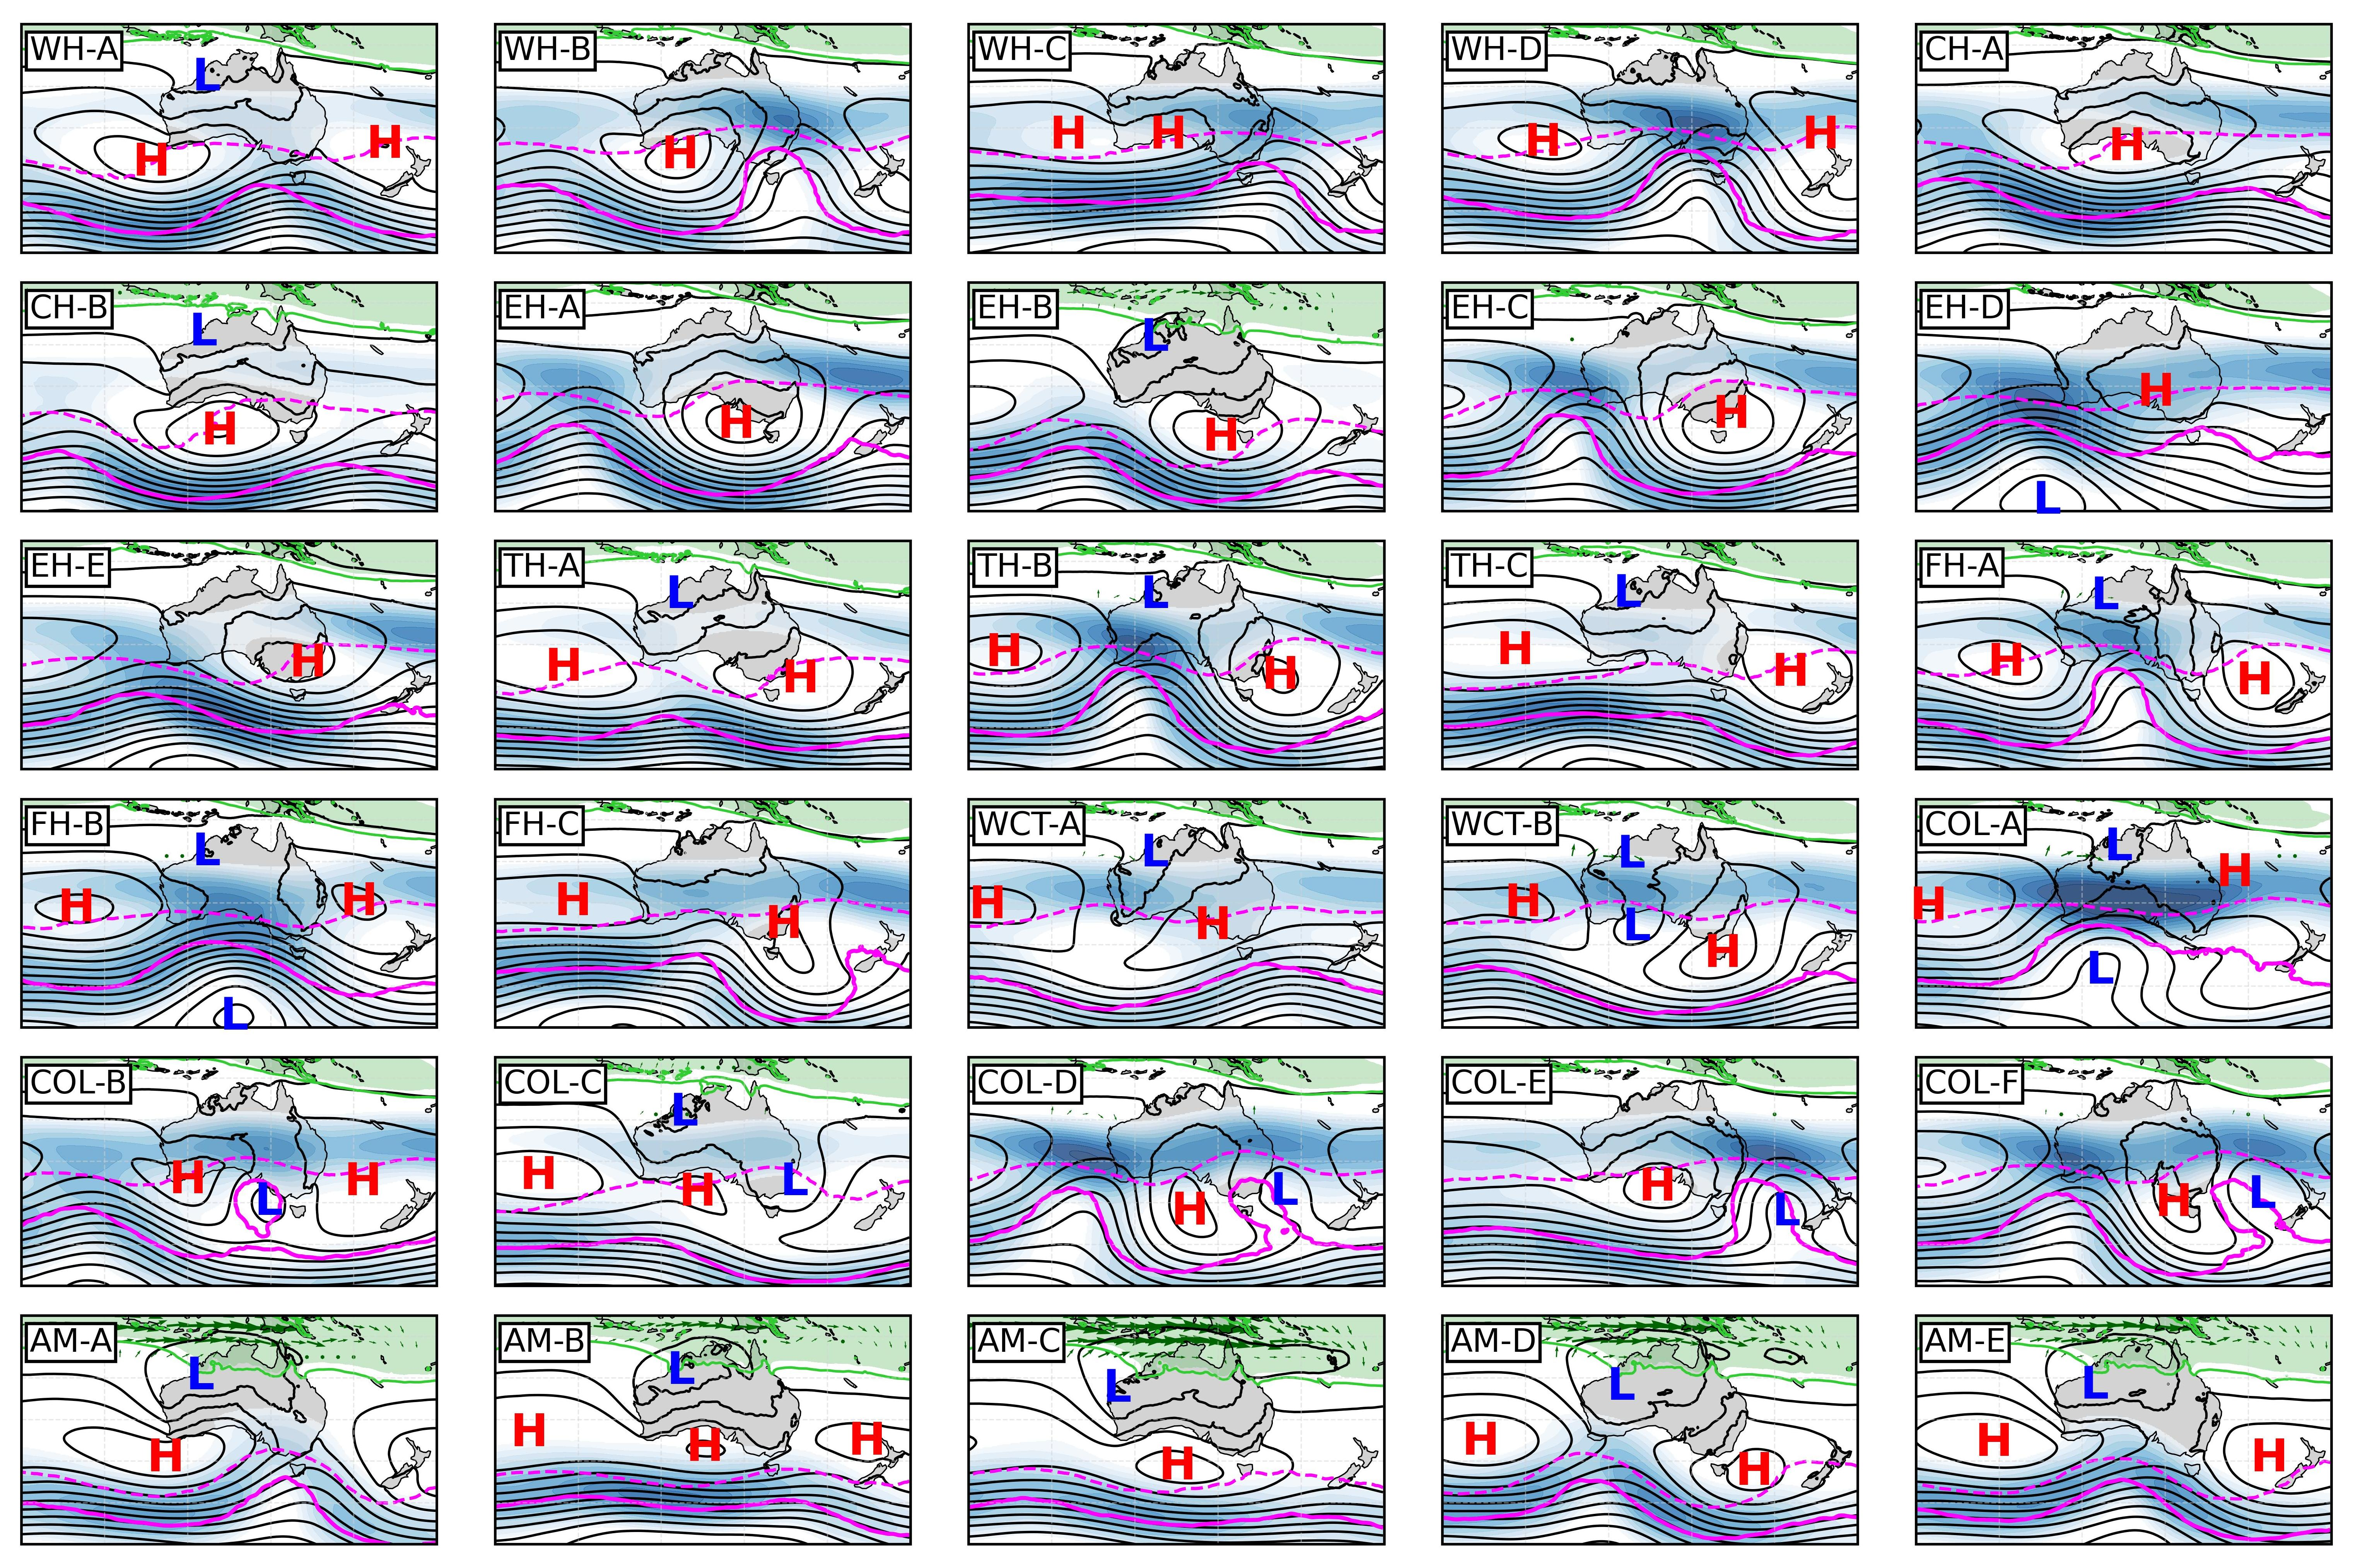
<i>Mean sea level pressure (black contours at 4 hPa intervals, vertically integrated water vapour greater than 48 $kg/m^2$ (green shading) and wind speed greater than 20$m/s$ (blue shading), 315 K (solid magenta) and 330 K (dashed magenta) 2 potential vorticity unit (PVU, 1 PVU = $10^{-6} m^2 s^{-1}K kg^{-1}$) contour. Closed lows (blue L) and highs (red H) in the mean sea level pressure field are also shown.</i>

This notebook rovides an overview of the tools and usage of the SWTs, including opening and usting the climatology and some basic plotting tools and use cases. Most notably, one can assign any 850hPa gridded wind field to a SWT, allowing users to use the SWT framework in most gridden model datasets. The full set of tools is provided and continually updated [here](https://github.com/21centuryweather/Australian-synoptic-weather-types).

In [1]:
import os
os.environ['WXSYSLIBDIR']='/g/data/gb02/mb0427/WxSysLib'
os.environ['SWTpath']='/home/565/mb0427/gdata-gb02/Australian_synoptic_weather_types/'
import sys
sys.path.append(os.environ['WXSYSLIBDIR'])
sys.path.append(os.environ['SWTpath'])

import xarray as xr
import pickle
import numpy as np
import pandas as pd

from datetime import datetime, timedelta
from dateutil.relativedelta import relativedelta

from plotting.plotting import plot_synoptic_ERA5, plot_synoptic_PVless_ERA5, SWTcolors

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
from cartopy.feature import NaturalEarthFeature, LAND

from assign.assign import assign_grid_to_SWT

# Datasets

Open the climatology of SWTs. The data is stored both in a netcdf and csv format called "SWT_climatology.nc" or "SWT_climatology.csv". Previous versions are additionally available in the github repository.

In [2]:
SWTs=xr.open_dataset(f"{os.environ['SWTpath']}/SWT_climatology/SWT_climatology.nc")

/g/data/xp65/admin/analysis3/sitecustomize.py:72: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  mod = _real_import(name, globals, locals, fromlist, level)


In [3]:
SWTs

<xarray.Dataset> Size: 761kB
Dimensions:       (time: 27149, SWTs: 30)
Coordinates:
  * time          (time) datetime64[ns] 217kB 1952-01-01T12:00:00 ... 2026-04...
  * SWTs          (SWTs) <U5 600B 'WH-A' 'WH-B' 'WH-C' ... 'AM-C' 'AM-D' 'AM-E'
Data variables:
    assigned_SWT  (time) <U5 543kB ...
Attributes:
    dataset:       Australian Synoptic Weather Types
    data source:   ERA5
    input data:    u-wind and v-wind on 850hPa
    last updated:  2026-08-27 15:31:32
    start month:   1952/01
    end month:     2026/04
    reference:     10.22541/essoar.174250748.85665142/v1
    created by:    Michael A. Barnes (ARC Centre of Excellence for 21st Centu...

Open the SWT dataset. This dataset comprises of the original set of 30 SWTs as described in the paper together with the wind centroids required in order to assign a grid to a SWT.
The data is stored both in a netcdf called "SWT_data.nc"

In [4]:
SWT_data=xr.open_dataset(f"{os.environ['SWTpath']}/SWT_fields/SWT_data.nc")

In [5]:
SWT_data

<xarray.Dataset> Size: 1MB
Dimensions:       (time: 26298, SWT: 30, latitude: 31, longitude: 44)
Coordinates:
  * time          (time) datetime64[ns] 210kB 1952-01-01T12:00:00 ... 2023-12...
  * SWT           (SWT) <U5 600B 'WH-A' 'WH-B' 'WH-C' ... 'AM-C' 'AM-D' 'AM-E'
  * latitude      (latitude) float32 124B -5.0 -6.5 -8.0 ... -47.0 -48.5 -50.0
  * longitude     (longitude) float32 176B 100.0 101.5 103.0 ... 163.0 164.5
Data variables:
    assigned_SWT  (time) <U5 526kB ...
    clusterU      (SWT, latitude, longitude) float32 164kB ...
    clusterV      (SWT, latitude, longitude) float32 164kB ...

# Handling the SWT dataset

Plot a synoptic composite from ERA5 together with the relevant SWT code from ERA5 data. Various plotting options are available within the github repository!

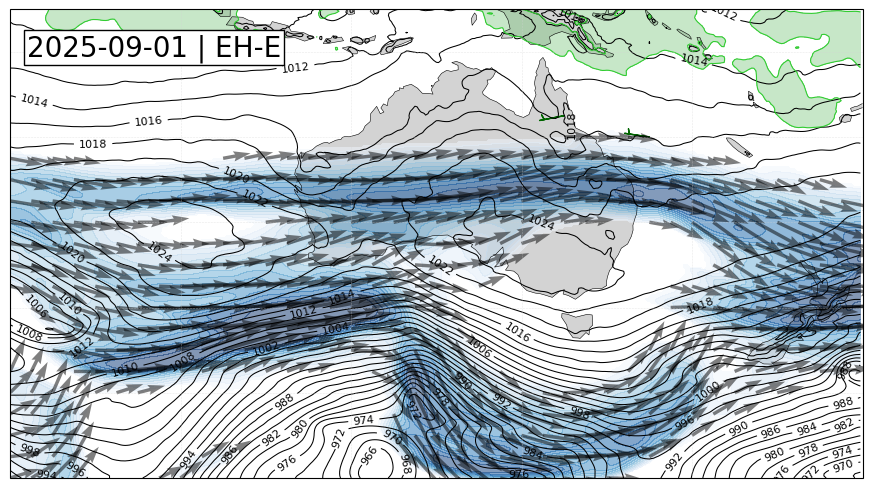

In [6]:
indt=datetime(2025,9,1,12)
indt_SWT=SWTs.sel(time=indt).assigned_SWT.item()
plot_synoptic_PVless_ERA5(indt_SWT,indt)

Now plot the seasonal distribution. Here I running mean seasonal distribution of the SWTs centred on the summer months to show how the SWTs change seasonally

In [7]:
inrundays=15 # Days to use for the running mean

clusters=xr.open_dataset(os.environ['SWTpath']+"SWT_climatology/SWT_climatology.nc")
clusters=clusters.sel(time=slice(datetime(1900,1,1),datetime(2025,1,1,0)))
SWTnames = clusters.SWTs # Get the names of the 30 synoptic types in teh typical order

cluster_series = clusters.assigned_SWT # Get the assigned daily SWT codes in the climatology
cluster_series.coords["mmdd"] = cluster_series["time"].dt.strftime("%m%d") # Get the day-month

grouped = cluster_series.groupby("mmdd") # Group by the day and month

mmdds=list(grouped.groups.keys())
mmdds.remove("0229") # Remove the extra leap year dates

def periodic_rolling_sum_centered(arr, window):
    arr = np.asarray(arr)
    
    pad = window // 2
    
    padded = np.pad(arr, (pad, pad), mode='wrap')
    
    kernel = np.ones(window, dtype=arr.dtype)
    out = np.convolve(padded, kernel, mode='valid')
    
    # If window is even, trim to original length
    return out[:len(arr)]

In [8]:
# Reorder and reorganise the data to prepare for plotting

reorder_st=np.where(np.array(mmdds)=='0801')[0][0]
mmdds=mmdds[reorder_st::]+mmdds[0:reorder_st]

cluster_labels=np.zeros((len(set(clusters.time.dt.year.values)),len(mmdds)))
cluster_spread=np.zeros((len(SWTnames),len(mmdds)))
for i,mmdd in enumerate(mmdds):
    selected_group = grouped.groups[mmdd]
    temp=cluster_series.isel(time=selected_group)
    cluster_labels[:,i] = xr.DataArray(
        pd.Categorical(
            temp.values,
            categories=SWTnames
        ).codes,
        coords=temp.coords,
        dims=temp.dims,
        name='assigned_SWT_index'
    )

for it,t in enumerate(range(cluster_labels.shape[1])):
    for im,m in enumerate(range(cluster_labels.shape[0])):
        SWTindex=int(cluster_labels[im,it])
        cluster_spread[SWTindex,it]=cluster_spread[SWTindex,it]+1

for im in range(cluster_spread.shape[0]):
    cluster_spread[im,:]=periodic_rolling_sum_centered(cluster_spread[im,:],inrundays)

cluster_spread_freq=cluster_spread/(inrundays*len(set(clusters.time.dt.year.values)))

datetimes=[datetime.strptime(mmdd,'%m%d') for mmdd in mmdds]
month_ticks = [i for i, date in enumerate(datetimes) if date.day == 1]
month_ticklabels=[datetimes[m].strftime('%b') for m in month_ticks]

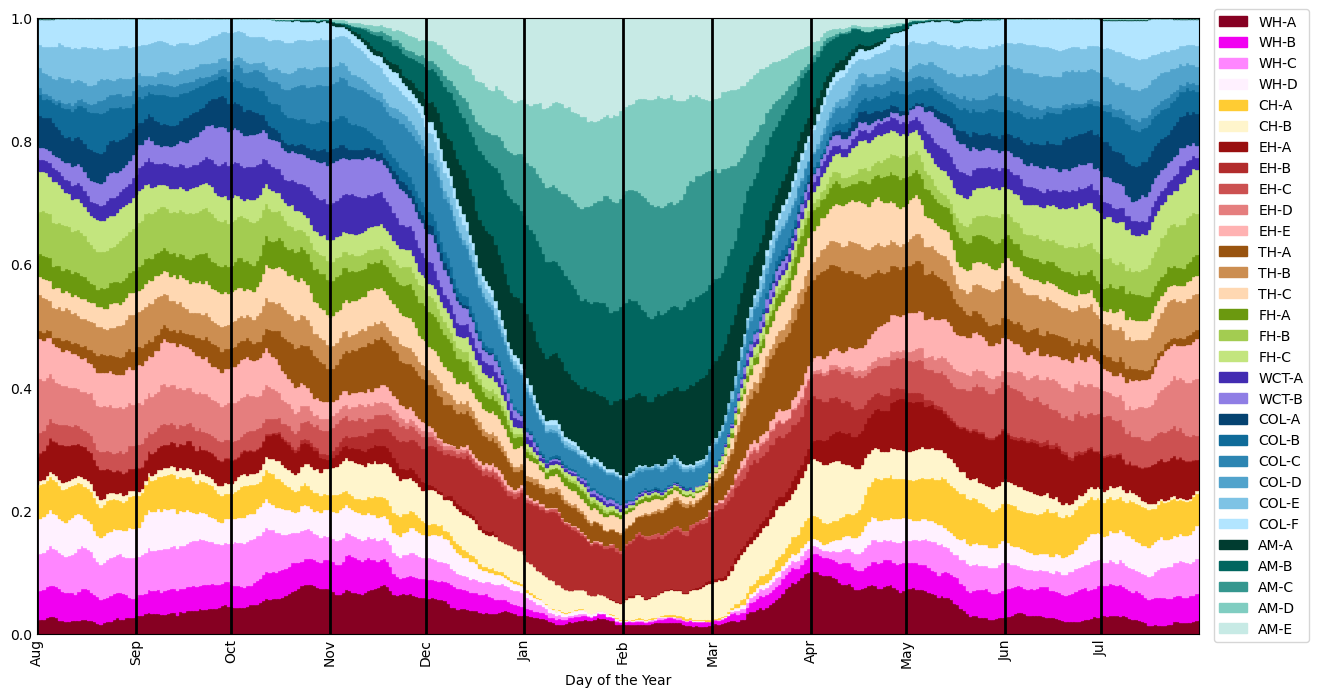

In [9]:
# Plot the seasonal distribution climatology as a timeseries

fig, ax = plt.subplots(figsize=(15, 8))

# Number of bars (columns)
num_bars = cluster_spread_freq.shape[1]
x = np.arange(num_bars)
bottom = np.zeros(num_bars)

regticks=[4,6,11,14,17,19,25]
for i, (row, color) in enumerate(zip(cluster_spread_freq, SWTcolors)):
    # Draw the bar
    bars = plt.bar(x, row, bottom=bottom, color=color, label=SWTnames.values[i],
                   edgecolor=color,   # removes outline
                   linewidth=1,       # extra safety
                  )
    bottom += row

ax.legend(loc='upper right', bbox_to_anchor=(1.10, 1.025), ncols=1)

#datestrings=cluster_series.time.dt.strftime('%Y-%m-%d').values
xticks=ax.set_xticks(month_ticks)
xticklabs=ax.set_xticklabels(month_ticklabels,rotation=90)
ax.set_xlabel('Day of the Year')
ax.tick_params(length=0) 

ax.grid(axis='x',color='k', linestyle='-', linewidth=2)

ax.set_xlim([0,len(datetimes)])
plt.show()

# Assigning a grid to a SWT

The Australian Synoptic Weather Types repository hosts a set of tools to assign any gridded 850hPa wind field to a SWT. This is done by "assign_grid_to_SWT" function. The function handles xarray dataarrays of u and v wind fileds and hdanles all grid interpolation. The result of running the function outputs the assigned SWT as a string and prints it out if required. Below is an example of using the assingment functionality using ECMWF IFS NWP data.

In [10]:
## Load the data

inpath=os.environ['SWTpath']+'example_data/'
ufn=inpath+'20250204120000-24h-enfo-ef_u_850_0.grib2'
u=xr.open_dataset(ufn,engine='cfgrib',backend_kwargs={'indexpath': ''}, decode_timedelta=True)

vfn=inpath+'20250204120000-24h-enfo-ef_v_850_0.grib2'
v=xr.open_dataset(vfn,engine='cfgrib',backend_kwargs={'indexpath': ''}, decode_timedelta=True)

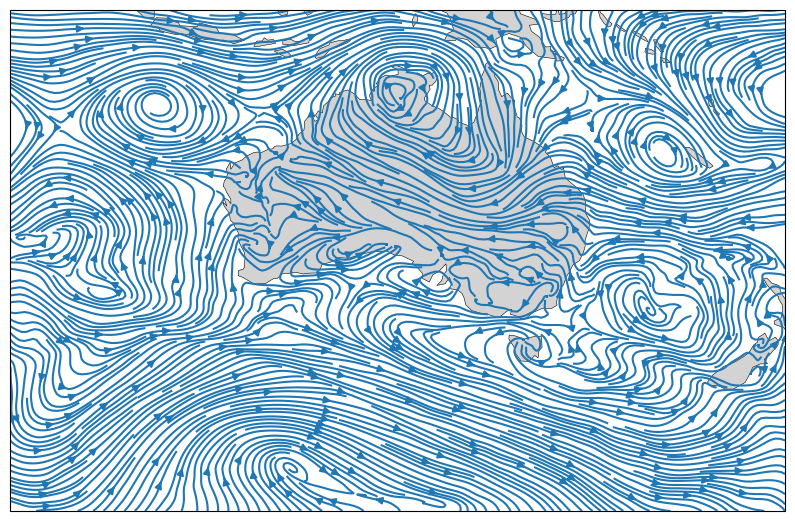

In [11]:
## Plot the 850hPa wind field to be assigned

u1=u.reindex(latitude=list(reversed(u.latitude))).sel(longitude=slice(80,180),latitude=slice(-65,0))
v1=v.reindex(latitude=list(reversed(v.latitude))).sel(longitude=slice(80,180),latitude=slice(-65,0))

fig, ax = plt.subplots(1, 1, figsize=(10,8), subplot_kw=dict(projection=ccrs.PlateCarree())) 
plot_extent=[90,175,-60,-5]
ax.set_extent(plot_extent,crs=ccrs.PlateCarree())
ax.streamplot(u1.longitude.values,u1.latitude.values,
               u1.u.values,
               v1.v.values, density=5)
ax.add_feature(LAND,facecolor='lightgrey')
ax.coastlines(linewidths=0.4)

plt.show()

Below is an example of how to assign any gridded field to a SWT. The inputs expected are u and v-wind fields in xarray dataarray format. The function automatically interpolates the dataset to a 1.5-degree grid. If your data matches the grid provided in the the "SWT_data.nc" file, you can set interpolation=False to avoid this part of the process.

In [13]:
SWT=assign_grid_to_SWT(u.u,v.v,latname="latitude",
                       lonname="longitude",
                       cluster_filename=os.environ['SWTpath']+"SWT_fields/SWT_data.nc",
                       quiet=False)

Synoptic Weather Type: AM-D


In [14]:
SWT

'AM-D'

Printing "assign_grid_to_SWT" function to show its usage and inputs

In [15]:
print(assign_grid_to_SWT.__doc__)

 Assign a 850hPa wind field to a Australian Synoptic Weather Type
     
    Created by Frans Liqui Lung (Monash University) and Michael A. Barnes (ARC CoE 21st Century Weather, Monash University)
    
    Parameters
    ----------
    
    u : xr.DataArray with shape (latitude,longitude) and dtype float64
        The 850hPa zonal wind field.
    v : xr.DataArray with shape (latitude,longitude) and dtype float64
        The 850hPa meridional wind field.
    
    Options
    -------
    
    latname : str (default: "latitude")
        Name of the latitude variable name in the input u and v DataArrays
    lonname : str (default: "longitude")
        Name of the longitude variable name in the input u and v DataArrays
    cluster_filename : str (default: "SWT_fields/SWT_data.nc")
        Location of the netcdf containing the clustered SWT fields.
    interpolate : bool (default: True)
        If false, does not do any interpolation on the grid. Note: if false, grids must be exactly the same